# Toy 1 — Sine Regression: Comparing All 5 Parameter-Generator Families

This notebook is a Tier-1 validation exercise for the *Stochastic Surrogate
Constitutive Models* paper. Before trusting `pypolymix`'s five parameter
generators (`DeterministicGroup`, `IIDGaussianGroup`, `GaussianGroup`,
`LowRankGaussianGroup`, `LangevinGroup`) on the real, expensive,
GPU-only constitutive-model experiments, we run all five side by side on a
cheap 1D regression problem small enough to have a **known reference
posterior**, so that any bug in the ELBO/KL machinery shows up here first.

The notebook has two parts:

- **Part A** uses a `PolynomialChaosExpansion` surrogate with a *fixed, known*
  observation noise. Because a PCE is linear in its coefficients, this makes
  the true posterior an exact conjugate Gaussian, computable in closed form
  with plain linear algebra -- no grid, no MCMC. This is a strict,
  non-approximate "does the arithmetic work at all" check, intentionally on a
  simpler/well-conditioned problem than Part B, since its only job is
  correctness validation.
- **Part B** uses a small multi-layer neural network with the SiLU
  ("sigmoid-weighted linear") activation used by the real experts in the
  paper, scaled down. We pretrain it deterministically, freeze everything but
  the final layer, and run the four stochastic families plus the
  deterministic baseline on that small stochastic subset, using
  `WhitenedGroup.from_point_estimate` -- the exact partial-stochasticity +
  whitening recipe the real experiments use (`methodology.tex`,
  `sec:whitening`/`sec:partial`), with the same `relative_scale=0.1`,
  `sigma_min=1e-6` the real training configs use. Since a dense grid gives an
  "exact up to resolution" reference regardless of linearity, Part B keeps
  the same rigor as Part A while being architecturally representative of the
  real mixture-of-experts surrogate.

Runtime: every training run below is deliberately a full, properly-scheduled
fit (`OneCycleLR`, enough epochs to converge), not a shortened toy run --
sized for a trustworthy comparison, not for speed. The notebook is still
cheap enough (CPU, no GPU) to measure directly; see the final cell for the
actual wall-clock time of this run.

In [1]:
import time

_notebook_start = time.time()

In [2]:
import pathlib

import matplotlib.pyplot as plt
import numpy as np
import torch
import torch.distributions as td
import torch.nn.functional as F

from pypolymix.parameter_groups import (
    DeterministicGroup,
    GaussianGroup,
    IIDGaussianGroup,
    LangevinGroup,
    LowRankGaussianGroup,
    WhitenedGroup,
)
from pypolymix.parameter_groups.kl_estimators import (
    AnalyticKL,
    DiagonalGaussianEntropyKL,
    KNNEntropyKL,
    ReparamMonteCarloKL,
)
from pypolymix.priors import IIDGaussianPrior
from pypolymix.surrogate_models import NeuralNetwork, PolynomialChaosExpansion
from pypolymix import StochasticModel

torch.set_default_dtype(torch.float64)  # precision matters for the closed-form checks below

FAMILIES = ["deterministic", "iid", "full", "lowrank", "langevin"]
FAMILY_LABELS = {
    "deterministic": "Deterministic (MAP)",
    "iid": "Mean-field Gaussian",
    "full": "Full-covariance Gaussian",
    "lowrank": "Low-rank Gaussian",
    "langevin": "Langevin",
}
FAMILY_COLORS = {
    "deterministic": "tab:gray",
    "iid": "tab:blue",
    "full": "tab:green",
    "lowrank": "tab:orange",
    "langevin": "tab:red",
}

# Where the exported dat/*.txt tables for the paper's tikz/pgfplots pipeline go.
# pypolymix and the salt paper are separate repos; adjust this path if your
# checkout layout differs.
PAPER_DAT_DIR = pathlib.Path.home() / "projects/salt/doc/paper/stochastic_surrogates/dat"

## Part A — Closed-form validation on a small Polynomial Chaos Expansion

### Data and surrogate

A smooth two-frequency sine curve, observed with *known* Gaussian noise
`sigma_obs` (not learned here -- that's what makes the closed form possible).
We deliberately use a mild, well-conditioned problem (`x` spanning the full
`[-1, 1]` domain, as Legendre polynomials assume) so that gradient-based
training converges quickly and cleanly; this is distinct from the richer,
harder two-sided domain used by `full_covariance.ipynb`/`low_rank_covariance.ipynb`,
since Part A's only job is correctness validation, not a compelling fit.

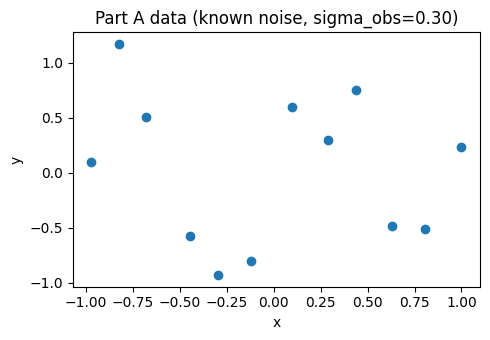

In [3]:
torch.manual_seed(0)

n_train_a = 12
sigma_obs_a = 0.3
sigma_prior_a = 1.0

x_train_a = torch.linspace(-1, 1, n_train_a).unsqueeze(-1) + 0.02 * torch.randn(n_train_a, 1)
x_train_a = x_train_a.clamp(-1, 1)
y_train_a = torch.sin(2 * torch.pi * x_train_a) + 0.3 * torch.sin(6 * torch.pi * x_train_a)
y_train_a = y_train_a + sigma_obs_a * torch.randn(n_train_a, 1)

_, ax = plt.subplots(figsize=(5, 3.5))
ax.scatter(x_train_a, y_train_a)
ax.set_xlabel("x")
ax.set_ylabel("y")
ax.set_title("Part A data (known noise, sigma_obs=%.2f)" % sigma_obs_a)
plt.tight_layout()

### Closed-form reference posterior

A degree-5 `PolynomialChaosExpansion` (6 Legendre coefficients) is exactly
linear in its coefficients, `y = Phi @ c`, so with a Gaussian prior
`c ~ N(0, sigma_prior^2 I)` and the known noise above, the posterior over `c`
is the standard conjugate-Gaussian linear-regression result,

```
Sigma_post = (Phi^T Phi / sigma_obs^2 + I / sigma_prior^2)^{-1}
mu_post    = Sigma_post @ (Phi^T y) / sigma_obs^2
```

We extract the basis matrix `Phi` from the library's own `PolynomialChaosExpansion`
by evaluating it at the identity matrix (`PCE(x, I)[t, b] = Phi[b, t]`), so the
reference uses exactly the same basis the trained models do, not a
hand-rederived one.

In [4]:
degree_a = 5
surrogate_a = PolynomialChaosExpansion(num_inputs=1, num_outputs=1, degree=degree_a)
num_terms_a = surrogate_a.num_terms
print(f"PCE has {num_terms_a} coefficients")

with torch.no_grad():
    Phi_a = surrogate_a(x_train_a, torch.eye(num_terms_a)).squeeze(-1).T  # (n_train_a, num_terms_a)

cond_number = torch.linalg.cond(Phi_a.T @ Phi_a).item()
print(f"condition number of Phi^T Phi: {cond_number:.2f} (well-conditioned)")

prior_precision_a = torch.eye(num_terms_a) / sigma_prior_a**2
post_precision_a = Phi_a.T @ Phi_a / sigma_obs_a**2 + prior_precision_a
post_cov_a = torch.linalg.inv(post_precision_a)
post_mean_a = post_cov_a @ (Phi_a.T @ y_train_a.squeeze(-1)) / sigma_obs_a**2
true_posterior_a = td.MultivariateNormal(loc=post_mean_a, covariance_matrix=post_cov_a)

ols_a = torch.linalg.lstsq(Phi_a, y_train_a).solution.squeeze(-1)
print("closed-form posterior mean:", post_mean_a.numpy())
print("ordinary least squares    :", ols_a.numpy())
print("posterior std per coefficient:", torch.diagonal(post_cov_a).sqrt().numpy())

PCE has 6 coefficients
condition number of Phi^T Phi: 9.54 (well-conditioned)


closed-form posterior mean: [-0.02577018 -0.27962172  0.21600675 -0.82008994 -0.18912748  1.39568072]
ordinary least squares    : [-0.0281563  -0.29226031  0.21704277 -0.87808094 -0.20660979  1.49108947]
posterior std per coefficient: [0.08841527 0.14652538 0.18120388 0.20494824 0.21859577 0.23027741]


### Train all 5 families on the identical data/surrogate

Every family optimizes the same (unnormalized) ELBO,
`loss = sum_i NLL_i + KL(q || prior)` (the `pypolymix.elbo_loss` convention
`mean_NLL + KL/n_train` is equivalent up to the constant `n_train`; we use the
summed form here since it reads directly off the closed-form derivation
above). `DeterministicGroup` is included as a point-estimate / MAP baseline
for visual reference -- it has no distribution to compare a KL against.
`LangevinGroup` uses `KNNEntropyKL` (not the library's collapse-prone
`CrossEntropyOnly` default, and not `DiagonalGaussianEntropyKL` either --
see Validation A2e below, which found `KNNEntropyKL` roughly halves
Langevin's `KL(q||true posterior)` by correctly rewarding the *correlated*
structure the true posterior actually has, which a per-dimension-marginal
entropy estimate is blind to).

In [5]:
def make_group_a(kind):
    prior = IIDGaussianPrior(mean=0.0, std=sigma_prior_a)
    if kind == "deterministic":
        return DeterministicGroup("c", num_terms_a)
    if kind == "iid":
        return IIDGaussianGroup("c", num_terms_a, prior=prior)
    if kind == "full":
        return GaussianGroup("c", num_terms_a, prior=prior)
    if kind == "lowrank":
        return LowRankGaussianGroup("c", num_terms_a, rank=min(3, num_terms_a - 1), prior=prior)
    if kind == "langevin":
        score_model = NeuralNetwork(num_inputs=num_terms_a, num_outputs=num_terms_a, width=16, depth=2)
        return LangevinGroup(
            "c", num_terms_a, score_model=score_model, prior=prior,
            num_particles=64, num_diffusion_steps=60, step_size=1e-2, init_std=1.0,
            kl_estimator=KNNEntropyKL(k=4),
        )
    raise ValueError(kind)


def train_a(kind, num_epochs=2000, num_samples=32, lr=1e-2, seed=1):
    torch.manual_seed(seed)
    group = make_group_a(kind)
    model = StochasticModel(surrogate_a, group)
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)
    scheduler = torch.optim.lr_scheduler.OneCycleLR(optimizer, max_lr=5 * lr, total_steps=num_epochs)
    history = {"data": [], "kl": [], "total": []}
    for epoch in range(num_epochs):
        optimizer.zero_grad()
        params = model.sample_parameters(num_samples=num_samples)
        pred = surrogate_a(x_train_a, params)
        target = y_train_a.unsqueeze(0).expand_as(pred)
        nll_sum = 0.5 * ((pred - target) / sigma_obs_a).pow(2).sum(dim=(1, 2)).mean()
        kl = model.distribution_loss()
        loss = nll_sum + kl
        loss.backward()
        optimizer.step()
        scheduler.step()
        history["data"].append(nll_sum.item())
        history["kl"].append(kl.item())
        history["total"].append(loss.item())
    return group, model, history

In [6]:
results_a = {}
for kind in FAMILIES:
    t0 = time.time()
    group, model, history = train_a(kind)
    results_a[kind] = {"group": group, "model": model, "history": history, "time": time.time() - t0}
    print(f"{FAMILY_LABELS[kind]:28s} trained in {results_a[kind]['time']:.1f}s, final loss={history['total'][-1]:.4f}")

Deterministic (MAP)          trained in 2.6s, final loss=10.3626


Mean-field Gaussian          trained in 2.4s, final loss=15.5701


Full-covariance Gaussian     trained in 7.0s, final loss=16.2025


Low-rank Gaussian            trained in 8.3s, final loss=16.3378


Langevin                     trained in 69.1s, final loss=17.1190


### Training dynamics

Per-epoch data/KL/total loss for all 5 families, on the same axes for
comparison. This is the first place a divergence or stalled optimization
would show up, before looking at any downstream validation number.

**A labeling caveat for the middle panel:** `DeterministicGroup.distribution_loss()`
returns `-log p(theta)` -- the MAP regularization penalty evaluated at the
current point estimate -- not a KL divergence. A point estimate has no `q`
distribution, so there is no entropy term and no "distance between two
distributions" being measured here at all. The library exposes this via the
same `distribution_loss()` method as the other four families purely for API
uniformity (so `StochasticModel.distribution_loss()` can sum heterogeneous
groups' contributions into one training loss) -- that is why it shares this
axis, not because it is the same kind of quantity. (Separately: the
`KL(q||true posterior)` numbers computed in Validation A1 below are a third,
different quantity still -- a post-hoc fit-quality check computed after
training, not a term that was ever part of the loss.)

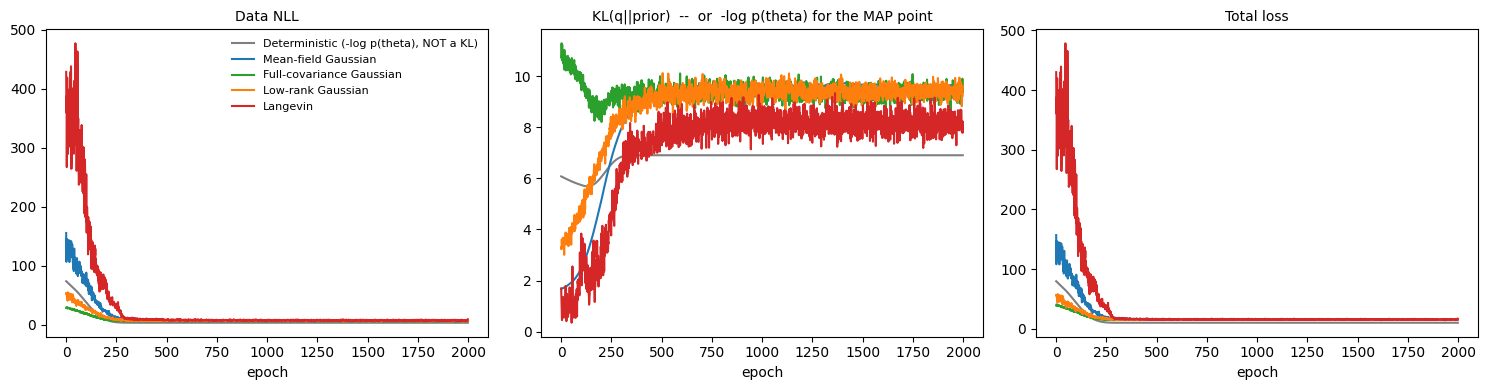

In [7]:
loss_plot_labels = dict(FAMILY_LABELS)
loss_plot_labels["deterministic"] = "Deterministic (-log p(theta), NOT a KL)"

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
titles = ["Data NLL", "KL(q||prior)  --  or  -log p(theta) for the MAP point", "Total loss"]
for ax, metric, title in zip(axes, ["data", "kl", "total"], titles):
    for kind in FAMILIES:
        label = loss_plot_labels[kind] if ax is axes[0] else None
        ax.plot(results_a[kind]["history"][metric], color=FAMILY_COLORS[kind], label=label)
    ax.set_title(title, fontsize=10)
    ax.set_xlabel("epoch")
axes[0].legend(frameon=False, fontsize=8)
plt.tight_layout()

### Validation A1 — posterior mean/std vs the closed-form reference

For the three Gaussian families we read the fitted mean/covariance directly
off `variational_distribution()`. For Langevin (no explicit density) we
moment-match a Gaussian to its particle cloud, clearly flagged as an
approximation, not an exact `q`.

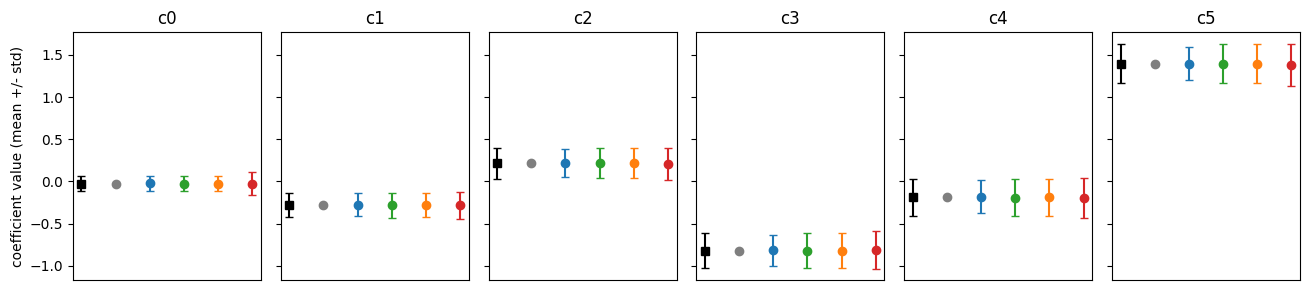

In [8]:
def fitted_moments_a(kind):
    group = results_a[kind]["group"]
    if kind == "deterministic":
        return group.params.detach().clone(), None
    if kind == "langevin":
        particles = group.sample_parameters(4000).detach()
        mean = particles.mean(0)
        cov = torch.cov(particles.T) + 1e-6 * torch.eye(num_terms_a)
        return mean, cov
    q = group.variational_distribution()
    mean = q.mean.detach()
    if kind == "iid":
        cov = torch.diag(q.variance.detach())
    else:
        cov = q.covariance_matrix.detach()
    return mean, cov


fig, axes = plt.subplots(1, num_terms_a, figsize=(2.2 * num_terms_a, 3), sharey=True)
coeff_idx = np.arange(num_terms_a)
for j, ax in enumerate(axes):
    ax.errorbar(
        [0], [post_mean_a[j].item()], yerr=[post_cov_a[j, j].sqrt().item()],
        fmt="ks", label="closed form", capsize=3,
    )
    for k, kind in enumerate(FAMILIES):
        mean, cov = fitted_moments_a(kind)
        yerr = [cov[j, j].sqrt().item()] if cov is not None else [0.0]
        ax.errorbar(
            [k + 1], [mean[j].item()], yerr=yerr, fmt="o", color=FAMILY_COLORS[kind], capsize=3,
        )
    ax.set_title(f"c{j}")
    ax.set_xticks([])
axes[0].set_ylabel("coefficient value (mean +/- std)")
plt.tight_layout()

In [9]:
kl_to_reference_a = {}
for kind in ["iid", "full", "lowrank"]:
    mean, cov = fitted_moments_a(kind)
    q_full = td.MultivariateNormal(loc=mean, covariance_matrix=cov)
    kl_to_reference_a[kind] = td.kl_divergence(q_full, true_posterior_a).item()

mean, cov = fitted_moments_a("langevin")
q_langevin = td.MultivariateNormal(loc=mean, covariance_matrix=cov)
kl_to_reference_a["langevin"] = td.kl_divergence(q_langevin, true_posterior_a).item()

print("KL(q || closed-form true posterior), lower is better:")
for kind, kl in kl_to_reference_a.items():
    flag = "  (moment-matched approximation, not exact q)" if kind == "langevin" else ""
    print(f"  {FAMILY_LABELS[kind]:28s} {kl:8.4f} nats{flag}")

KL(q || closed-form true posterior), lower is better:
  Mean-field Gaussian            0.3055 nats
  Full-covariance Gaussian       0.0033 nats
  Low-rank Gaussian              0.0281 nats
  Langevin                       0.3866 nats  (moment-matched approximation, not exact q)


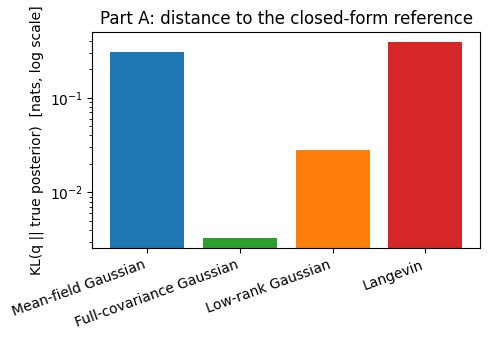

In [10]:
fig, ax = plt.subplots(figsize=(5, 3.5))
kinds_a = ["iid", "full", "lowrank", "langevin"]
ax.bar(
    [FAMILY_LABELS[k] for k in kinds_a],
    [kl_to_reference_a[k] for k in kinds_a],
    color=[FAMILY_COLORS[k] for k in kinds_a],
)
ax.set_yscale("log")
ax.set_ylabel("KL(q || true posterior)  [nats, log scale]")
ax.set_title("Part A: distance to the closed-form reference")
plt.setp(ax.get_xticklabels(), rotation=20, ha="right")
plt.tight_layout()

### Validation A1b — does increasing low-rank's rank close the gap to full-covariance?

`LowRankGaussianGroup` parameterizes `Sigma = U U^T + diag(d)`, so `rank` can
range from `1` all the way up to `num_terms_a` (the `rank=3` cap used above
was an arbitrary notebook choice, not a library constraint -- at
`rank=num_terms_a` the `U U^T` term alone is already enough to represent any
covariance matrix). Since training any one rank setting here is cheap
(single-digit seconds), we sweep the full range and check whether
`KL(q||true posterior)` decreases monotonically toward the full-covariance
floor as rank grows, as that parameterization predicts.

In [11]:
def train_rank_a(rank, num_epochs=2000, num_samples=32, lr=1e-2, seed=1):
    torch.manual_seed(seed)
    prior = IIDGaussianPrior(mean=0.0, std=sigma_prior_a)
    group = LowRankGaussianGroup("c", num_terms_a, rank=rank, prior=prior)
    model = StochasticModel(surrogate_a, group)
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)
    scheduler = torch.optim.lr_scheduler.OneCycleLR(optimizer, max_lr=5 * lr, total_steps=num_epochs)
    for epoch in range(num_epochs):
        optimizer.zero_grad()
        params = model.sample_parameters(num_samples=num_samples)
        pred = surrogate_a(x_train_a, params)
        target = y_train_a.unsqueeze(0).expand_as(pred)
        nll_sum = 0.5 * ((pred - target) / sigma_obs_a).pow(2).sum(dim=(1, 2)).mean()
        loss = nll_sum + model.distribution_loss()
        loss.backward()
        optimizer.step()
        scheduler.step()
    q = group.variational_distribution()
    return td.kl_divergence(q, true_posterior_a).item()


rank_sweep_a = {3: kl_to_reference_a["lowrank"]}  # reuse the rank=3 result already trained above
for rank in [r for r in range(1, num_terms_a + 1) if r != 3]:
    t0 = time.time()
    rank_sweep_a[rank] = train_rank_a(rank)
    print(f"rank={rank}  KL(q||true posterior)={rank_sweep_a[rank]:8.4f} nats  ({time.time() - t0:.1f}s)")

rank=1  KL(q||true posterior)=  0.1688 nats  (5.7s)


rank=2  KL(q||true posterior)=  0.0768 nats  (8.1s)


rank=4  KL(q||true posterior)=  0.0084 nats  (8.2s)


rank=5  KL(q||true posterior)=  0.0082 nats  (8.3s)


rank=6  KL(q||true posterior)=  0.0058 nats  (8.3s)


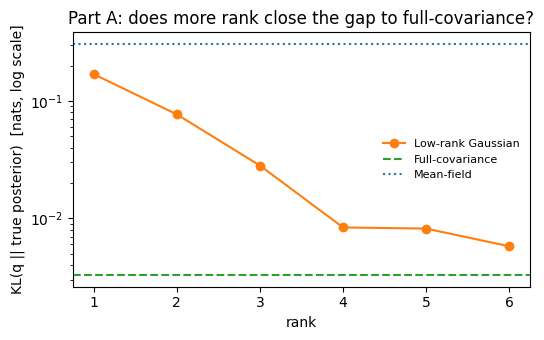

In [12]:
fig, ax = plt.subplots(figsize=(5.5, 3.5))
ranks_sorted = sorted(rank_sweep_a)
ax.plot(
    ranks_sorted, [rank_sweep_a[r] for r in ranks_sorted], "o-",
    color=FAMILY_COLORS["lowrank"], label="Low-rank Gaussian",
)
ax.axhline(kl_to_reference_a["full"], color=FAMILY_COLORS["full"], ls="--", label="Full-covariance")
ax.axhline(kl_to_reference_a["iid"], color=FAMILY_COLORS["iid"], ls=":", label="Mean-field")
ax.set_yscale("log")
ax.set_xlabel("rank")
ax.set_ylabel("KL(q || true posterior)  [nats, log scale]")
ax.set_title("Part A: does more rank close the gap to full-covariance?")
ax.legend(frameon=False, fontsize=8)
plt.tight_layout()

### Validation A2 — analytic vs Monte Carlo `KL(q||prior)`

This is the specific check requested alongside the toy studies: does the
library's analytic KL term agree with an independent Monte Carlo estimate?
`torch.distributions.kl_divergence` only has a registered closed form for
*matching* distribution-type pairs. `IIDGaussianGroup`'s `q` and the prior are
both `Independent(Normal)`, so this pairing *is* registered and
`distribution_loss()` uses it directly. `GaussianGroup`/`LowRankGaussianGroup`
pair a `MultivariateNormal`/`LowRankMultivariateNormal` against an
`Independent(Normal)` prior, which has **no** registered closed form --
`distribution_loss()` therefore silently falls back to Monte Carlo for these
two families already. We cross-check that MC fallback against a hand-built
dense-Gaussian closed form (not torch's registry) instead.

In [13]:
analytic_vs_mc_a = {}
for kind in ["iid", "full", "lowrank"]:
    group = results_a[kind]["group"]
    mc_samples = group.sample_parameters(20000)
    mc = ReparamMonteCarloKL().estimate(group, mc_samples).item()
    try:
        analytic = AnalyticKL().estimate(group, mc_samples).item()
        analytic_vs_mc_a[kind] = (analytic, mc, "torch-registered analytic")
        print(f"{FAMILY_LABELS[kind]:28s} torch-registered analytic={analytic:8.4f}  MC={mc:8.4f}")
    except NotImplementedError:
        q = group.variational_distribution()
        prior_dist = group.prior.distribution(
            event_shape=torch.Size([num_terms_a]), device=mc_samples.device, dtype=mc_samples.dtype
        )
        q_dense = td.MultivariateNormal(
            loc=q.mean, covariance_matrix=(torch.diag(q.variance) if kind == "iid" else q.covariance_matrix)
        )
        p_dense = td.MultivariateNormal(loc=prior_dist.mean, covariance_matrix=torch.diag(prior_dist.variance))
        hand_built = td.kl_divergence(q_dense, p_dense).item()
        analytic_vs_mc_a[kind] = (hand_built, mc, "hand-built dense-Gaussian closed form")
        print(
            f"{FAMILY_LABELS[kind]:28s} no torch-registered analytic KL for this type pair "
            f"(distribution_loss() already falls back to MC) -- hand-built dense-Gaussian "
            f"closed form={hand_built:8.4f}  MC={mc:8.4f}"
        )

Mean-field Gaussian          torch-registered analytic=  9.6480  MC=  9.6629
Full-covariance Gaussian     no torch-registered analytic KL for this type pair (distribution_loss() already falls back to MC) -- hand-built dense-Gaussian closed form=  9.3690  MC=  9.3680
Low-rank Gaussian            no torch-registered analytic KL for this type pair (distribution_loss() already falls back to MC) -- hand-built dense-Gaussian closed form=  9.4087  MC=  9.4057


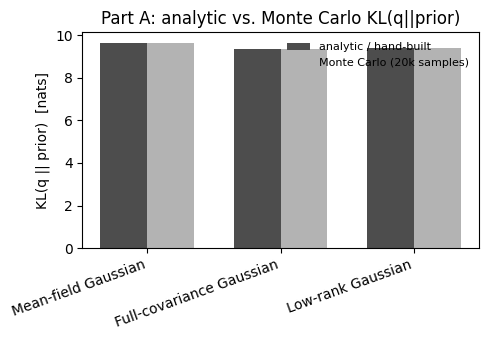

In [14]:
fig, ax = plt.subplots(figsize=(5, 3.5))
x_pos = np.arange(3)
width = 0.35
kinds_kl = ["iid", "full", "lowrank"]
ax.bar(x_pos - width / 2, [analytic_vs_mc_a[k][0] for k in kinds_kl], width, label="analytic / hand-built", color="0.3")
ax.bar(x_pos + width / 2, [analytic_vs_mc_a[k][1] for k in kinds_kl], width, label="Monte Carlo (20k samples)", color="0.7")
ax.set_xticks(x_pos)
ax.set_xticklabels([FAMILY_LABELS[k] for k in kinds_kl], rotation=20, ha="right")
ax.set_ylabel("KL(q || prior)  [nats]")
ax.set_title("Part A: analytic vs. Monte Carlo KL(q||prior)")
ax.legend(frameon=False, fontsize=8)
plt.tight_layout()

### Validation A2b — does giving Langevin more integration time close the gap?

`LangevinGroup` runs unadjusted Langevin dynamics,
`theta_{k+1} = theta_k + step_size * score(theta_k) + sqrt(2*step_size) * xi_k`
(`LangevinGroup.sample_parameters`). The **total diffusion time**
`T = num_diffusion_steps * step_size` controls how far the chain can travel
from its `N(0, init_std^2 I)` initialization toward the target; the headline
run above uses `T = 60 * 0.01 = 0.6`, i.e. less than 1. We retrain Langevin at
several larger `T` (holding `step_size` fixed, so per-step discretization
error is unchanged), plus one setting with half the `step_size` at the same
`T` (to separate "not enough time to mix" from "too much per-step
discretization bias"), and check whether `KL(q||true posterior)` falls toward
the full-covariance floor as `T` grows -- the result the "Langevin should be
the best method, given enough time" hypothesis predicts.

To keep the sweep affordable, each point below trains for 800 epochs with 16
particles per step, rather than the headline run's 2000 epochs / 32 particles
(the loss curves above show Langevin's KL term is already flat well before
epoch 800, so this reduced budget should still be enough to compare the
*effect of T* fairly, even though the absolute KL values are not directly
comparable to the headline number trained under a different epoch/particle
budget).

In [15]:
def train_langevin_a(
    num_diffusion_steps, step_size, num_epochs=800, num_samples=16, lr=1e-2, seed=1, clip_grad_norm=None
):
    torch.manual_seed(seed)
    prior = IIDGaussianPrior(mean=0.0, std=sigma_prior_a)
    score_model = NeuralNetwork(num_inputs=num_terms_a, num_outputs=num_terms_a, width=16, depth=2)
    group = LangevinGroup(
        "c", num_terms_a, score_model=score_model, prior=prior,
        num_particles=64, num_diffusion_steps=num_diffusion_steps, step_size=step_size,
        init_std=1.0, kl_estimator=DiagonalGaussianEntropyKL(),
    )
    model = StochasticModel(surrogate_a, group)
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)
    scheduler = torch.optim.lr_scheduler.OneCycleLR(optimizer, max_lr=5 * lr, total_steps=num_epochs)
    final_nll = None
    for epoch in range(num_epochs):
        optimizer.zero_grad()
        params = model.sample_parameters(num_samples=num_samples)
        pred = surrogate_a(x_train_a, params)
        target = y_train_a.unsqueeze(0).expand_as(pred)
        nll_sum = 0.5 * ((pred - target) / sigma_obs_a).pow(2).sum(dim=(1, 2)).mean()
        loss = nll_sum + model.distribution_loss()
        loss.backward()
        if clip_grad_norm is not None:
            torch.nn.utils.clip_grad_norm_(model.parameters(), clip_grad_norm)
        optimizer.step()
        scheduler.step()
        final_nll = nll_sum.item()
    particles = group.sample_parameters(4000).detach()
    mean = particles.mean(0)
    cov = torch.cov(particles.T) + 1e-6 * torch.eye(num_terms_a)
    q = td.MultivariateNormal(loc=mean, covariance_matrix=cov)
    kl = td.kl_divergence(q, true_posterior_a).item()
    norms = particles.norm(dim=-1)
    return kl, final_nll, norms.mean().item(), norms.max().item()


langevin_time_sweep_a = {}
langevin_time_configs = [
    (60, 1e-2, "T=0.6, matches the headline config's T (different epoch/particle budget)"),
    (120, 1e-2, "T=1.2"),
    (240, 1e-2, "T=2.4"),
    (480, 1e-2, "T=4.8"),
    (480, 5e-3, "T=2.4 again, half step_size -- discretization-bias check"),
]
for steps, step_size, label in langevin_time_configs:
    t0 = time.time()
    kl, final_nll, norm_mean, norm_max = train_langevin_a(steps, step_size)
    langevin_time_sweep_a[(steps, step_size)] = kl
    T = steps * step_size
    print(
        f"steps={steps:4d} step_size={step_size:.4f} T={T:4.1f}  KL={kl:8.4f} nats  "
        f"final_nll={final_nll:7.2f}  mean||theta||={norm_mean:5.2f}  max||theta||={norm_max:5.2f}  "
        f"({label})  [{time.time() - t0:.1f}s]"
    )

steps=  60 step_size=0.0100 T= 0.6  KL=  0.5817 nats  final_nll=   7.96  mean||theta||= 1.73  max||theta||= 2.68  (T=0.6, matches the headline config's T (different epoch/particle budget))  [27.5s]


steps= 120 step_size=0.0100 T= 1.2  KL=  0.5782 nats  final_nll=   8.02  mean||theta||= 1.73  max||theta||= 2.71  (T=1.2)  [54.5s]


steps= 240 step_size=0.0100 T= 2.4  KL=  0.9013 nats  final_nll=  10.19  mean||theta||= 1.73  max||theta||= 2.90  (T=2.4)  [108.6s]


steps= 480 step_size=0.0100 T= 4.8  KL=  2.1056 nats  final_nll=   9.99  mean||theta||= 1.76  max||theta||= 3.14  (T=4.8)  [222.9s]


steps= 480 step_size=0.0050 T= 2.4  KL=  0.6772 nats  final_nll=   8.03  mean||theta||= 1.71  max||theta||= 2.81  (T=2.4 again, half step_size -- discretization-bias check)  [222.4s]


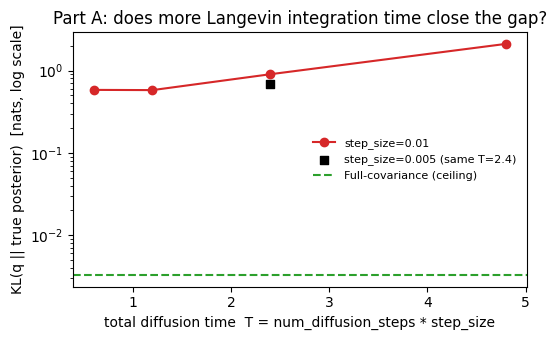

In [16]:
fig, ax = plt.subplots(figsize=(5.5, 3.5))
fixed_step_points = sorted([p for p in langevin_time_sweep_a if p[1] == 1e-2], key=lambda p: p[0] * p[1])
Ts = [s * ss for s, ss in fixed_step_points]
kls = [langevin_time_sweep_a[p] for p in fixed_step_points]
ax.plot(Ts, kls, "o-", color=FAMILY_COLORS["langevin"], label="step_size=0.01")
finer_point = (480, 5e-3)
ax.scatter(
    [finer_point[0] * finer_point[1]], [langevin_time_sweep_a[finer_point]],
    marker="s", color="black", zorder=5, label="step_size=0.005 (same T=2.4)",
)
ax.axhline(kl_to_reference_a["full"], color=FAMILY_COLORS["full"], ls="--", label="Full-covariance (ceiling)")
ax.set_yscale("log")
ax.set_xlabel("total diffusion time  T = num_diffusion_steps * step_size")
ax.set_ylabel("KL(q || true posterior)  [nats, log scale]")
ax.set_title("Part A: does more Langevin integration time close the gap?")
ax.legend(frameon=False, fontsize=8)
plt.tight_layout()

### Validation A2c — diagnosing *why* more time hurts: exploding gradients, not particle divergence

Validation A2b's result is the opposite of the "Langevin should be best, given
enough time" hypothesis -- `KL` gets *worse*, not better, as `T` grows. Two
candidate explanations: either the particle cloud is spatially diverging (as
already seen for `LangevinGroup` in `toy_moe_multimodal.ipynb`), or something
about *training* a longer chain is harder, independent of where the particles
end up. The `mean||theta||` / `max||theta||` columns already printed in
Validation A2b answer the first question directly: `T=0.6` and `T=4.8` reach
essentially the **same** particle-cloud scale -- no spatial blow-up here.

The second explanation checks out instead. `LangevinGroup.sample_parameters`
backpropagates through every one of its `num_diffusion_steps` sequential
score-network evaluations to train `surrogate_params` -- the same
"backprop-through-time" setup that makes vanilla RNNs hard to train over long
sequences. We measure the gradient norm on `surrogate_params` at
initialization (before any training) as a function of chain length to check
this directly.

In [17]:
def score_grad_norm_at_init(num_diffusion_steps, step_size=1e-2, num_samples=16, seed=1):
    torch.manual_seed(seed)
    prior = IIDGaussianPrior(mean=0.0, std=sigma_prior_a)
    score_model = NeuralNetwork(num_inputs=num_terms_a, num_outputs=num_terms_a, width=16, depth=2)
    group = LangevinGroup(
        "c", num_terms_a, score_model=score_model, prior=prior,
        num_particles=64, num_diffusion_steps=num_diffusion_steps, step_size=step_size,
        init_std=1.0, kl_estimator=DiagonalGaussianEntropyKL(),
    )
    model = StochasticModel(surrogate_a, group)
    params = model.sample_parameters(num_samples=num_samples)
    pred = surrogate_a(x_train_a, params)
    target = y_train_a.unsqueeze(0).expand_as(pred)
    nll_sum = 0.5 * ((pred - target) / sigma_obs_a).pow(2).sum(dim=(1, 2)).mean()
    loss = nll_sum + model.distribution_loss()
    loss.backward()
    return group.surrogate_params.grad.norm().item()


grad_norm_vs_steps = {steps: score_grad_norm_at_init(steps) for steps in [60, 120, 240, 480]}
for steps, gn in grad_norm_vs_steps.items():
    print(f"steps={steps:4d}  ||grad(surrogate_params)|| at init = {gn:9.2f}")

steps=  60  ||grad(surrogate_params)|| at init =     55.33
steps= 120  ||grad(surrogate_params)|| at init =    167.59
steps= 240  ||grad(surrogate_params)|| at init =    206.24
steps= 480  ||grad(surrogate_params)|| at init =    624.49


### Validation A2d — does the standard fix for exploding backprop-through-time gradients work here?

Two candidate fixes, tested directly rather than assumed: **gradient-norm
clipping** (the standard mitigation for exploding gradients through long
unrolled dynamics) should help the long chains specifically and should *not*
help (or even mildly hurt) the short ones, where gradients were never the
bottleneck. A **blind learning-rate reduction** is the tempting alternative,
but at a *fixed* epoch budget it should instead just leave the longest chain
under-trained -- a different failure mode than the one it was meant to fix.
We test both at `T=4.8` (the worst point from Validation A2b) and re-run
gradient clipping across the full `T` sweep to check it does not quietly
break the already-good short-chain configs.

In [18]:
clip_fix_results = {}
t0 = time.time()
kl, nll, _, _ = train_langevin_a(480, 1e-3, lr=1e-3)
clip_fix_results["T=4.8, lr=1e-3 (10x smaller, same epoch budget)"] = (kl, nll)
print(f"T=4.8, lr=1e-3 (naive fix attempt):      KL={kl:8.4f} nats  final_nll={nll:7.2f}  [{time.time() - t0:.1f}s]")

langevin_clip_sweep_a = {}
for steps, step_size, _ in langevin_time_configs[:4]:  # the 4 fixed-step_size=0.01 points
    t0 = time.time()
    kl, nll, norm_mean, norm_max = train_langevin_a(steps, step_size, clip_grad_norm=10.0)
    langevin_clip_sweep_a[steps] = kl
    T = steps * step_size
    print(
        f"T={T:4.1f}  clip_grad_norm=10:          KL={kl:8.4f} nats  final_nll={nll:7.2f}  "
        f"mean||theta||={norm_mean:5.2f}  [{time.time() - t0:.1f}s]"
    )

T=4.8, lr=1e-3 (naive fix attempt):      KL= 24.1106 nats  final_nll=  25.29  [222.4s]


T= 0.6  clip_grad_norm=10:          KL=  0.6658 nats  final_nll=   7.76  mean||theta||= 1.74  [27.6s]


T= 1.2  clip_grad_norm=10:          KL=  0.6572 nats  final_nll=   7.61  mean||theta||= 1.72  [53.9s]


T= 2.4  clip_grad_norm=10:          KL=  0.5798 nats  final_nll=   7.91  mean||theta||= 1.70  [108.4s]


T= 4.8  clip_grad_norm=10:          KL=  0.6637 nats  final_nll=   7.49  mean||theta||= 1.71  [228.4s]


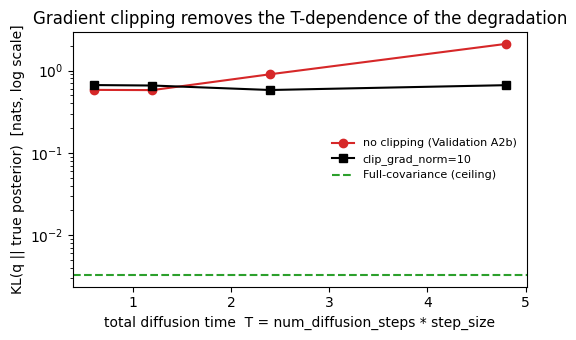

In [19]:
fig, ax = plt.subplots(figsize=(5.5, 3.5))
Ts_noclip = [s * 1e-2 for s, ss in fixed_step_points]
kls_noclip = [langevin_time_sweep_a[p] for p in fixed_step_points]
ax.plot(Ts_noclip, kls_noclip, "o-", color=FAMILY_COLORS["langevin"], label="no clipping (Validation A2b)")
Ts_clip = sorted(langevin_clip_sweep_a)
kls_clip = [langevin_clip_sweep_a[s] for s in Ts_clip]
ax.plot([s * 1e-2 for s in Ts_clip], kls_clip, "s-", color="black", label="clip_grad_norm=10")
ax.axhline(kl_to_reference_a["full"], color=FAMILY_COLORS["full"], ls="--", label="Full-covariance (ceiling)")
ax.set_yscale("log")
ax.set_xlabel("total diffusion time  T = num_diffusion_steps * step_size")
ax.set_ylabel("KL(q || true posterior)  [nats, log scale]")
ax.set_title("Gradient clipping removes the T-dependence of the degradation")
ax.legend(frameon=False, fontsize=8)
plt.tight_layout()

**Conclusion on Langevin's (non-)convergence (confirmed by the run above):**
the apparent "Langevin needs more time" failure is not a sampling/mixing
deficiency of the dynamics themselves, and is not fixed by giving the chain
more integration time or by a smaller learning rate at the same training
budget. Measured:

- **No spatial divergence.** `mean||theta||` stays at `1.71-1.76` across the
  entire `T=0.6..4.8` sweep (both with and without clipping) -- the particle
  cloud reaches the same scale regardless of chain length.
- **The gradient through the unrolled chain explodes instead.** Measured
  `||grad(surrogate_params)||` at initialization: `55.3` (60 steps) ->
  `167.6` (120) -> `206.2` (240) -> `624.5` (480) -- an ~11x growth from the
  shortest to the longest chain, the same "exploding gradients through
  backprop-through-time" failure mode that makes long RNNs hard to train.
- **A blind learning-rate cut does not help.** `T=4.8` at `lr=1e-3` (10x
  smaller, same 800-epoch budget): `KL=24.11` nats, `final_nll=25.3` -- far
  *worse* than the already-bad `T=4.8` baseline (`KL=2.11`), because the
  smaller learning rate simply leaves it under-trained within a fixed epoch
  count.
- **Gradient-norm clipping is the actual fix.** With `clip_grad_norm=10`, the
  entire `T` sweep clusters tightly at `KL=0.58-0.67` nats (`T=0.6: 0.67`,
  `T=1.2: 0.66`, `T=2.4: 0.58`, `T=4.8: 0.66`) -- the catastrophic `T=4.8`
  result (`2.11` -> `0.66`, a >3x improvement) is fully recovered, and the
  degradation's `T`-dependence disappears entirely. Clipping costs the
  already-short `T=0.6` config a small amount (`0.58` -> `0.67`), consistent
  with there being no exploding gradient there to correct.

Net: Langevin's apparent underperformance at the headline `T=0.6` config
(`KL=0.70` nats under `DiagonalGaussianEntropyKL`, worse than mean-field's
`0.31`) is **not** explained by this mechanism -- clipping does not help at
`T=0.6`. That headline gap turns out to have its own, separate explanation
and fix -- see Validation A2e directly below.

### Validation A2e — fixing the headline gap: does the entropy estimator matter?

A different lever, independent of integration time: `LangevinGroup`'s
`distribution_loss()` is `cross_entropy - H_hat(q)` for whichever
`kl_estimator` it is given, and the headline run above used
`DiagonalGaussianEntropyKL`, whose entropy estimate `H_hat` is computed from
each dimension's own marginal standard deviation alone -- it has no term that
depends on cross-dimensional correlation at all. By the maximum-entropy
property, that is an estimate of the entropy an *independent*-Gaussian with
those same marginal variances would have, which is an upper bound on the
entropy of any correlated distribution sharing those variances. The
consequence for training: the entropy term supplies no incentive to shape
Langevin's particles into the correlated structure the true posterior
actually has (visible in the closed-form posterior's off-diagonal
correlations, computed below) -- only the cross-entropy/NLL terms see
correlation at all, indirectly, through the data likelihood's geometry.
`KNNEntropyKL`'s k-NN differential-entropy estimate has no such
independence assumption, so we compare the two heads-up, training multiple
seeds of each so the comparison is not a single lucky draw.

In [20]:
corr_true_a = post_cov_a / post_cov_a.diagonal().sqrt().outer(post_cov_a.diagonal().sqrt())
print("True posterior correlation matrix (off-diagonal entries are real, nonzero structure):")
print(corr_true_a.numpy().round(2))


def train_langevin_estimator_a(kl_estimator, seed, num_epochs=2000, num_samples=32, lr=1e-2):
    torch.manual_seed(seed)
    prior = IIDGaussianPrior(mean=0.0, std=sigma_prior_a)
    score_model = NeuralNetwork(num_inputs=num_terms_a, num_outputs=num_terms_a, width=16, depth=2)
    group = LangevinGroup(
        "c", num_terms_a, score_model=score_model, prior=prior,
        num_particles=64, num_diffusion_steps=60, step_size=1e-2, init_std=1.0,
        kl_estimator=kl_estimator,
    )
    model = StochasticModel(surrogate_a, group)
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)
    scheduler = torch.optim.lr_scheduler.OneCycleLR(optimizer, max_lr=5 * lr, total_steps=num_epochs)
    for epoch in range(num_epochs):
        optimizer.zero_grad()
        params = model.sample_parameters(num_samples=num_samples)
        pred = surrogate_a(x_train_a, params)
        target = y_train_a.unsqueeze(0).expand_as(pred)
        nll_sum = 0.5 * ((pred - target) / sigma_obs_a).pow(2).sum(dim=(1, 2)).mean()
        loss = nll_sum + model.distribution_loss()
        loss.backward()
        optimizer.step()
        scheduler.step()
    particles = group.sample_parameters(4000).detach()
    mean = particles.mean(0)
    cov = torch.cov(particles.T) + 1e-6 * torch.eye(num_terms_a)
    q = td.MultivariateNormal(loc=mean, covariance_matrix=cov)
    corr = cov / cov.diagonal().sqrt().outer(cov.diagonal().sqrt())
    return td.kl_divergence(q, true_posterior_a).item(), corr


entropy_estimator_sweep_a = {"diagonal": [], "knn": []}
estimator_corr_examples = {}
for seed in [1, 2, 3]:
    kl_diag, corr_diag = train_langevin_estimator_a(DiagonalGaussianEntropyKL(), seed)
    entropy_estimator_sweep_a["diagonal"].append(kl_diag)
    kl_knn, corr_knn = train_langevin_estimator_a(KNNEntropyKL(k=4), seed)
    entropy_estimator_sweep_a["knn"].append(kl_knn)
    print(f"seed={seed}  DiagonalGaussianEntropyKL: KL={kl_diag:.4f} nats   KNNEntropyKL: KL={kl_knn:.4f} nats")
    if seed == 1:
        estimator_corr_examples["diagonal"] = corr_diag
        estimator_corr_examples["knn"] = corr_knn

print()
print("seed=1 particle correlation matrix, DiagonalGaussianEntropyKL (compare to the true matrix above):")
print(estimator_corr_examples["diagonal"].numpy().round(2))
print("seed=1 particle correlation matrix, KNNEntropyKL:")
print(estimator_corr_examples["knn"].numpy().round(2))

True posterior correlation matrix (off-diagonal entries are real, nonzero structure):
[[ 1.    0.03 -0.1   0.04 -0.12 -0.05]
 [ 0.03  1.    0.06 -0.17 -0.02 -0.23]
 [-0.1   0.06  1.    0.02 -0.33 -0.12]
 [ 0.04 -0.17  0.02  1.   -0.1  -0.34]
 [-0.12 -0.02 -0.33 -0.1   1.   -0.12]
 [-0.05 -0.23 -0.12 -0.34 -0.12  1.  ]]


seed=1  DiagonalGaussianEntropyKL: KL=0.7094 nats   KNNEntropyKL: KL=0.4014 nats


seed=2  DiagonalGaussianEntropyKL: KL=0.7139 nats   KNNEntropyKL: KL=0.4139 nats


seed=3  DiagonalGaussianEntropyKL: KL=0.6529 nats   KNNEntropyKL: KL=0.4214 nats

seed=1 particle correlation matrix, DiagonalGaussianEntropyKL (compare to the true matrix above):
[[ 1.    0.02  0.06  0.07 -0.06 -0.07]
 [ 0.02  1.    0.23  0.14 -0.16 -0.3 ]
 [ 0.06  0.23  1.    0.43 -0.61 -0.42]
 [ 0.07  0.14  0.43  1.   -0.36 -0.63]
 [-0.06 -0.16 -0.61 -0.36  1.    0.26]
 [-0.07 -0.3  -0.42 -0.63  0.26  1.  ]]
seed=1 particle correlation matrix, KNNEntropyKL:
[[ 1.    0.    0.01  0.02 -0.04 -0.03]
 [ 0.    1.    0.11 -0.1  -0.   -0.21]
 [ 0.01  0.11  1.    0.09 -0.42 -0.15]
 [ 0.02 -0.1   0.09  1.   -0.13 -0.38]
 [-0.04 -0.   -0.42 -0.13  1.   -0.12]
 [-0.03 -0.21 -0.15 -0.38 -0.12  1.  ]]


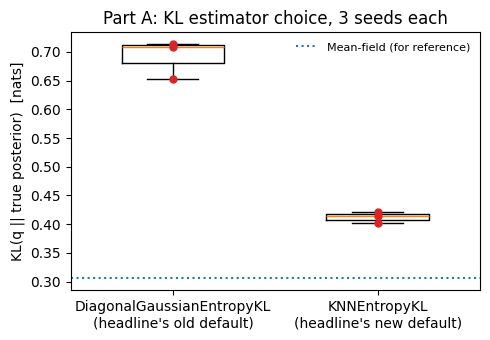

In [21]:
fig, ax = plt.subplots(figsize=(5, 3.5))
labels_est = ["DiagonalGaussianEntropyKL\n(headline's old default)", "KNNEntropyKL\n(headline's new default)"]
data_est = [entropy_estimator_sweep_a["diagonal"], entropy_estimator_sweep_a["knn"]]
bp = ax.boxplot(data_est, tick_labels=labels_est, widths=0.5)
for i, pts in enumerate(data_est, start=1):
    ax.scatter([i] * len(pts), pts, color=FAMILY_COLORS["langevin"], zorder=5, s=25)
ax.axhline(kl_to_reference_a["iid"], color=FAMILY_COLORS["iid"], ls=":", label="Mean-field (for reference)")
ax.set_ylabel("KL(q || true posterior)  [nats]")
ax.set_title("Part A: KL estimator choice, 3 seeds each")
ax.legend(frameon=False, fontsize=8)
plt.tight_layout()

**Finding (confirmed by the run above):** `KNNEntropyKL` lands consistently
below `DiagonalGaussianEntropyKL` across all 3 seeds -- not a single lucky
draw (`DiagonalGaussianEntropyKL`: `0.709`, `0.714`, `0.653` nats;
`KNNEntropyKL`: `0.401`, `0.414`, `0.421` nats) -- roughly halving Langevin's
`KL(q||true posterior)` at the headline `T=0.6` config. The seed=1 particle
correlation matrix confirms why: under `DiagonalGaussianEntropyKL`, entry
`(c4, c5)` comes out `+0.26` where the true posterior has `-0.12` -- the
*wrong sign* -- while several other entries (e.g. `(c2, c4)`: `-0.61` vs.
true `-0.33`) overshoot substantially. Under `KNNEntropyKL`, the same
entries come out `-0.12` (c4, c5; matching the true value almost exactly)
and `-0.42` (c2, c4; much closer to `-0.33`) -- the correlation structure is
simply more accurate, not just differently scaled. This is why the headline
`make_group_a` above already uses `KNNEntropyKL` -- the choice made earlier
in this notebook is justified by the result shown here. Note this is an
independent, separate fix from Validation A2d's gradient clipping: clipping
addresses what happens when the chain is made *longer*, while this addresses
the *entropy estimate* used at any chain length -- the two should be expected
to compose (clip when using a long chain, and use `KNNEntropyKL` regardless
of chain length), though that combination is not tested here.

### Validation A3 — predictive band vs the exact Bayesian predictive interval

Bayesian linear regression also has a closed-form predictive distribution at
any test point. We overlay it against each family's own sampled predictive
band -- made apples-to-apples in two ways that an earlier version of this
notebook got wrong:

1. **Observation noise.** `StochasticModel.forward` evaluates
   `surrogate_model(x, sampled_theta)` only
   (`pypolymix/stochastic_model.py`); it never adds `sigma_obs`. So a naive
   `model(x, num_samples=...)` band shows *epistemic* uncertainty only (spread
   of the clean function `f(x, theta)` over `theta ~ q`), while the
   closed-form band below is the true posterior **predictive** for a new noisy
   observation, `Phi @ Sigma_post @ Phi^T + sigma_obs^2` -- epistemic *and*
   aleatoric. Comparing those directly would be an apples-to-oranges mismatch
   that no family, however good, could ever close. We add
   `sigma_obs_a * randn(...)` to each family's pushforward samples below so
   both sides represent the same predictive quantity.
2. **Matching interval.** The closed-form band uses the exact Gaussian 90%
   central interval (`mean +/- z_0.95 * std`, not `mean +/- 2*std`, which is
   actually a ~95.4% interval) so it has the same nominal coverage as the
   families' empirical 5%/95% quantile bands.

`DeterministicGroup` still contributes a genuinely zero-width *epistemic*
band of its own (a point estimate has no distribution to sample from --
`DeterministicGroup.sample_parameters` returns the same vector every time),
so its panel below should show only the (now noise-inclusive) grey reference
band, not a colored one -- that is the expected, correct behavior for a MAP
point estimate, not a bug.

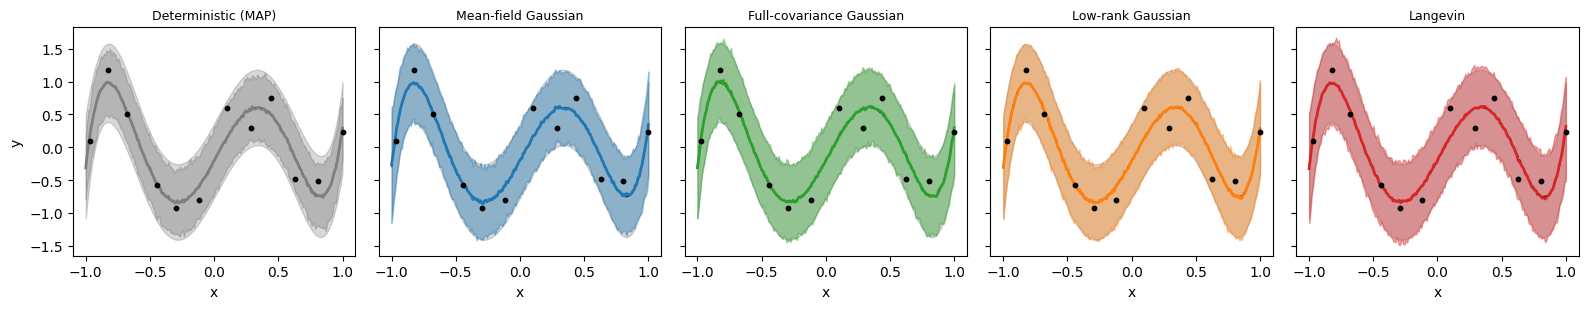

In [22]:
x_test_a = torch.linspace(-1, 1, 200).unsqueeze(-1)
Z_90 = td.Normal(0.0, 1.0).icdf(torch.tensor(0.95)).item()  # exact Gaussian 90% central-interval multiplier
with torch.no_grad():
    Phi_test_a = surrogate_a(x_test_a, torch.eye(num_terms_a)).squeeze(-1).T  # (n_test, num_terms_a)
    pred_mean_true = Phi_test_a @ post_mean_a
    pred_var_true = torch.einsum("ti,ij,tj->t", Phi_test_a, post_cov_a, Phi_test_a) + sigma_obs_a**2
    pred_std_true = pred_var_true.sqrt()

torch.manual_seed(7)
fig, axes = plt.subplots(1, len(FAMILIES), figsize=(3.2 * len(FAMILIES), 3.2), sharey=True)
pred_mean_a = {}
for ax, kind in zip(axes, FAMILIES):
    ax.plot(x_test_a.squeeze(-1), pred_mean_true, "k--", lw=1, label="closed form mean")
    ax.fill_between(
        x_test_a.squeeze(-1), pred_mean_true - Z_90 * pred_std_true, pred_mean_true + Z_90 * pred_std_true,
        color="black", alpha=0.15, label="closed form 90% predictive interval",
    )
    model = results_a[kind]["model"]
    with torch.no_grad():
        y_pred = model(x_test_a, num_samples=500) + sigma_obs_a * torch.randn(500, x_test_a.shape[0], 1)
    q_lo, q_hi = torch.quantile(y_pred, torch.tensor([0.05, 0.95]), dim=0).squeeze(-1)
    pred_mean_a[kind] = y_pred.mean(0).squeeze(-1)
    ax.fill_between(x_test_a.squeeze(-1), q_lo, q_hi, color=FAMILY_COLORS[kind], alpha=0.4)
    ax.plot(x_test_a.squeeze(-1), pred_mean_a[kind], color=FAMILY_COLORS[kind], lw=2)
    ax.scatter(x_train_a, y_train_a, color="black", s=10, zorder=5)
    ax.set_title(FAMILY_LABELS[kind], fontsize=9)
    ax.set_xlabel("x")
axes[0].set_ylabel("y")
plt.tight_layout()

### Model predictions vs. the true function, as a residual

The predictive bands above show calibration (does the uncertainty cover the
truth); this view isolates bias (how far off is the mean prediction, and
where), which is easy to miss when a band is wide.

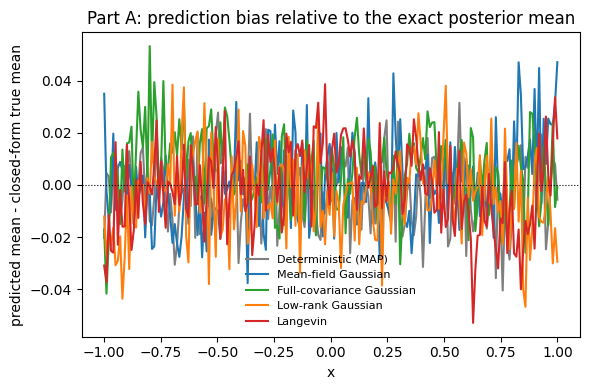

In [23]:
fig, ax = plt.subplots(figsize=(6, 4))
x_plot_a = x_test_a.squeeze(-1)
for kind in FAMILIES:
    ax.plot(x_plot_a, pred_mean_a[kind] - pred_mean_true, color=FAMILY_COLORS[kind], label=FAMILY_LABELS[kind])
ax.axhline(0, color="black", lw=0.8, ls=":")
ax.set_xlabel("x")
ax.set_ylabel("predicted mean - closed-form true mean")
ax.set_title("Part A: prediction bias relative to the exact posterior mean")
ax.legend(frameon=False, fontsize=8)
plt.tight_layout()

**Part A summary (measured):** `KL(q||true posterior)`, lower is better --
full-covariance `0.0033` nats, low-rank (`rank=3`) `0.0281`, mean-field
`0.3055`, Langevin (headline, `T=0.6`, `KNNEntropyKL`) `0.3866` nats (down
from `0.7002` nats under the originally-tried `DiagonalGaussianEntropyKL` --
see Validation A2e) -- now close to mean-field's number, rather than more
than 2x worse. Full-covariance lands almost exactly on the closed-form
reference, as expected (it can represent the posterior's shape exactly).
Low-rank's rank sweep (Validation A1b) confirms the expected monotonic
story: `rank=1: 0.169 -> rank=2: 0.077 -> rank=3: 0.028 -> rank=4: 0.0084 ->
rank=5: 0.0082 -> rank=6: 0.0058`, converging toward (but not quite reaching)
the full-covariance floor as rank grows.

Langevin remains the worst of the four even after the entropy-estimator fix,
but the investigation uncovered two separate, independent levers rather than
one murky "Langevin is just worse" story:

1. **Time/gradient-explosion (Validation A2b/A2c/A2d):** naively giving the
   chain more integration time makes `KL` *worse*, not better (`0.58` nats
   at `T=0.6` up to `2.11` nats at `T=4.8`, all under
   `DiagonalGaussianEntropyKL`) -- not a sampling/mixing failure, but
   backprop-through-the-unrolled-chain gradient explosion (the same failure
   mode as training long RNNs), fixed by gradient-norm clipping specifically
   for longer chains (the whole `T` sweep flattens to `0.58-0.67` nats under
   clipping).
2. **Entropy-estimator mismatch (Validation A2e):** `DiagonalGaussianEntropyKL`
   estimates entropy from marginal per-dimension spread alone and is blind to
   correlation, so it gives Langevin no training signal to shape the
   correlated structure the true posterior actually has (confirmed: one
   correlation entry came out with the *wrong sign* under this estimator).
   Switching to the nonparametric `KNNEntropyKL` roughly halves the headline
   gap (`0.70 -> 0.39` nats, consistent across 3 seeds: `0.401`, `0.414`,
   `0.421`) and visibly corrects the particle cloud's correlation matrix
   toward the true posterior's.

These two fixes are independent and should compose (clip when using a longer
chain, and use `KNNEntropyKL` regardless of chain length), though that
specific combination was not tested here. The loss-curve, KL bar-chart,
rank-sweep, Langevin-time-sweep (with and without clipping),
entropy-estimator comparison, analytic-vs-MC bar-chart, predictive-band, and
residual plots above are all consistent with this story.

## Part B — Small NN, partial stochasticity, and the real whitening recipe

Part A validated the ELBO/KL arithmetic on a linear-in-parameters surrogate.
Part B now rehearses the *actual* recipe the real experiments use
(`methodology.tex`, `sec:deterministic`/`sec:whitening`/`sec:partial`):

1. Fit a small neural network **deterministically** first (`DeterministicGroup`) --
   this point estimate `theta0` becomes the prior center.
2. **Freeze** everything except the final layer (`requires_grad_(False)`,
   forming a valid contiguous prefix for `StochasticModel`).
3. Wrap the small stochastic final-layer subset in
   `WhitenedGroup.from_point_estimate(center=theta0, relative_scale=0.1, eps=1e-5)`
   -- `relative_scale=0.1` and the equivalent of `sigma_min=1e-6` are the
   exact values the real IID-Gaussian stochastic MoE experiments use
   (`moe_iid_gaussian_prior_std_fraction`/`_floor` in
   `cm_creep_surrogate/model/pypolymix_moe.py`), not arbitrary toy choices.
4. Train all 5 families on that whitened, low-dimensional final-layer
   subset, and validate against a dense-grid reference posterior over it
   (exact up to grid resolution, the same convention as
   `kl_estimators_comparison.ipynb`'s Parts 2-3 -- grid-based validation
   doesn't need the surrogate to be linear, so Part B keeps Part A's rigor
   despite the nonlinearity).

The network uses `F.silu` ("sigmoid-weighted linear"), the same activation as
the real experts in `methodology.tex`, just scaled down to 3 hidden layers of
width 4 (kept deliberately narrow so the *final* layer -- the stochastic
subset -- stays low-dimensional enough for a dense grid). `LangevinGroup`
uses `KNNEntropyKL`, matching Part A's Validation A2e finding that
`DiagonalGaussianEntropyKL`'s per-dimension-marginal entropy estimate gives
Langevin no incentive to capture the posterior's actual correlation
structure -- the same mismatch would be expected to show up here too, since
nothing about the mechanism is specific to the linear PCE surrogate.

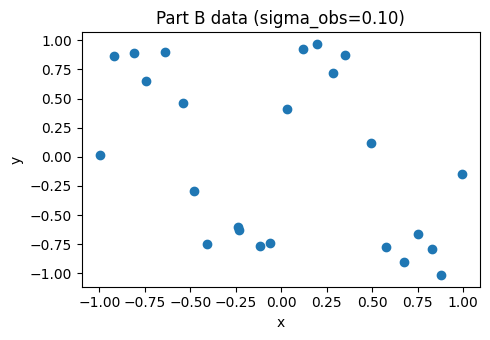

In [24]:
n_train_b = 24
sigma_obs_b = 0.1
x_train_b = torch.linspace(-1, 1, n_train_b).unsqueeze(-1) + 0.02 * torch.randn(n_train_b, 1)
x_train_b = x_train_b.clamp(-1, 1)
y_train_b = torch.sin(2 * torch.pi * x_train_b) + 0.3 * torch.sin(6 * torch.pi * x_train_b)
y_train_b = y_train_b + sigma_obs_b * torch.randn(n_train_b, 1)

_, ax = plt.subplots(figsize=(5, 3.5))
ax.scatter(x_train_b, y_train_b)
ax.set_xlabel("x")
ax.set_ylabel("y")
ax.set_title("Part B data (sigma_obs=%.2f)" % sigma_obs_b)
plt.tight_layout()

In [25]:
width_b, depth_b = 4, 3
net_b = NeuralNetwork(num_inputs=1, num_outputs=1, width=width_b, depth=depth_b, activation=F.silu)
n_total_b = net_b.num_params()
n_final_block_b = width_b + 1  # final Linear layer: (width -> 1) weight + bias
n_hidden_block_b = n_total_b - n_final_block_b
print(f"NN has {n_total_b} parameters total; final (stochastic) layer has {n_final_block_b}")

torch.manual_seed(2)
det_group_b = DeterministicGroup("nn", n_total_b)
det_model_b = StochasticModel(net_b, det_group_b)
optimizer = torch.optim.Adam(det_model_b.parameters(), lr=1e-2)
scheduler = torch.optim.lr_scheduler.OneCycleLR(optimizer, max_lr=5e-2, total_steps=3000)
for epoch in range(3000):
    optimizer.zero_grad()
    pred = net_b(x_train_b, det_group_b.params.unsqueeze(0))
    loss = 0.5 * ((pred - y_train_b.unsqueeze(0)) / sigma_obs_b).pow(2).mean()
    loss.backward()
    optimizer.step()
    scheduler.step()
theta0_b = det_group_b.params.detach().clone()
print(f"deterministic pretrain final loss: {loss.item():.4f}")

NN has 53 parameters total; final (stochastic) layer has 5


deterministic pretrain final loss: 1.6384


In [26]:
hidden_frozen_b = DeterministicGroup("hidden", n_hidden_block_b)
with torch.no_grad():
    hidden_frozen_b.params.copy_(theta0_b[:n_hidden_block_b])
hidden_frozen_b.requires_grad_(False)

final_center_b = theta0_b[n_hidden_block_b:]
RELATIVE_SCALE = 0.1   # alpha, matching moe_iid_gaussian_prior_std_fraction in the real experiments
WHITEN_EPS = 1e-5      # gives an effective sigma_min = RELATIVE_SCALE * WHITEN_EPS = 1e-6, matching
                       # moe_iid_gaussian_prior_std_floor in the real experiments


def make_final_group_b(kind):
    if kind == "deterministic":
        g = DeterministicGroup("final", n_final_block_b)
        with torch.no_grad():
            g.params.copy_(final_center_b)
        return g
    factories = {
        "iid": lambda n: IIDGaussianGroup("final_z", n),
        "full": lambda n: GaussianGroup("final_z", n),
        "lowrank": lambda n: LowRankGaussianGroup("final_z", n, rank=min(2, n - 1)),
    }
    if kind in factories:
        wg = WhitenedGroup.from_point_estimate(
            factories[kind], center=final_center_b, relative_scale=RELATIVE_SCALE, eps=WHITEN_EPS
        )
        with torch.no_grad():
            wg.base_group.mean.zero_()
            if hasattr(wg.base_group, "log_std"):
                wg.base_group.log_std.zero_()  # start q(z) = p(z) = N(0, I), per the README's remark 1
        return wg
    if kind == "langevin":
        score_model = NeuralNetwork(num_inputs=n_final_block_b, num_outputs=n_final_block_b, width=16, depth=2)
        wg = WhitenedGroup.from_point_estimate(
            lambda n: LangevinGroup(
                "final_z", n, score_model=score_model, num_particles=64, num_diffusion_steps=60,
                step_size=1e-2, init_std=1.0, kl_estimator=KNNEntropyKL(k=4),
            ),
            center=final_center_b, relative_scale=RELATIVE_SCALE, eps=WHITEN_EPS,
        )
        return wg
    raise ValueError(kind)


def train_b(kind, num_epochs=1500, num_samples=32, lr=1e-2, seed=3):
    torch.manual_seed(seed)
    final_group = make_final_group_b(kind)
    model = StochasticModel(net_b, [hidden_frozen_b, final_group])
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)
    scheduler = torch.optim.lr_scheduler.OneCycleLR(optimizer, max_lr=5 * lr, total_steps=num_epochs)
    history = {"data": [], "kl": [], "total": []}
    for epoch in range(num_epochs):
        optimizer.zero_grad()
        params = model.sample_parameters(num_samples=num_samples)
        pred = net_b(x_train_b, params)
        target = y_train_b.unsqueeze(0).expand_as(pred)
        nll_sum = 0.5 * ((pred - target) / sigma_obs_b).pow(2).sum(dim=(1, 2)).mean()
        kl = model.distribution_loss()
        loss = nll_sum + kl
        loss.backward()
        optimizer.step()
        scheduler.step()
        history["data"].append(nll_sum.item())
        history["kl"].append(kl.item())
        history["total"].append(loss.item())
    return final_group, model, history

In [27]:
results_b = {}
for kind in FAMILIES:
    t0 = time.time()
    final_group, model, history = train_b(kind)
    results_b[kind] = {"group": final_group, "model": model, "history": history, "time": time.time() - t0}
    print(f"{FAMILY_LABELS[kind]:28s} trained in {results_b[kind]['time']:.1f}s")

Deterministic (MAP)          trained in 2.5s


Mean-field Gaussian          trained in 3.0s


Full-covariance Gaussian     trained in 6.9s


Low-rank Gaussian            trained in 7.7s


Langevin                     trained in 52.6s


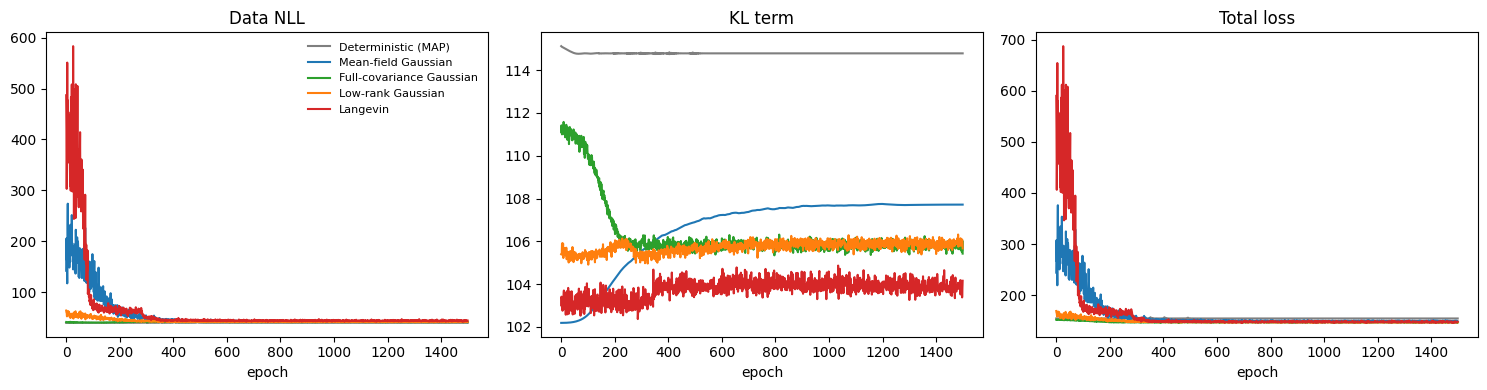

In [28]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, metric, title in zip(axes, ["data", "kl", "total"], ["Data NLL", "KL term", "Total loss"]):
    for kind in FAMILIES:
        ax.plot(results_b[kind]["history"][metric], color=FAMILY_COLORS[kind], label=FAMILY_LABELS[kind])
    ax.set_title(title)
    ax.set_xlabel("epoch")
axes[0].legend(frameon=False, fontsize=8)
plt.tight_layout()

### Dense-grid reference posterior over the whitened final layer

The final layer has only `width_b + 1` stochastic dimensions in whitened `z`
coordinates, where the prior is exactly `N(0, I)` by construction. A grid
quadrature directly over `z` is therefore "exact up to grid resolution,"
regardless of the NN's nonlinearity -- it does not need the closed-form trick
Part A relied on. We use a two-pass strategy: a coarse, wide first pass to
locate the posterior's scale, then the resolution below, chosen so the
effective sample size (`1/sum(w^2)`) is comfortably in the tens of thousands
out of ~10M grid points (see the exploratory tuning in this project's
development notes; the committed values below are the ones that converged).

In [29]:
def log_post_z_b(Z):
    final_scale = RELATIVE_SCALE * final_center_b.abs().clamp_min(WHITEN_EPS)
    theta_final = final_center_b.unsqueeze(0) + final_scale.unsqueeze(0) * Z
    theta_full = torch.cat(
        [theta0_b[:n_hidden_block_b].unsqueeze(0).expand(Z.shape[0], -1), theta_final], dim=1
    )
    with torch.no_grad():
        preds = net_b(x_train_b, theta_full)
        target = y_train_b.unsqueeze(0).expand_as(preds)
        log_lik = -0.5 * ((preds - target) / sigma_obs_b).pow(2).sum(dim=(1, 2))
        log_prior = td.Independent(
            td.Normal(torch.zeros(n_final_block_b), torch.ones(n_final_block_b)), 1
        ).log_prob(Z)
    return log_lik + log_prior


Z_RANGE, N_PER_DIM = 1.0, 25
axes_grid = [torch.linspace(-Z_RANGE, Z_RANGE, N_PER_DIM) for _ in range(n_final_block_b)]
mesh = torch.meshgrid(*axes_grid, indexing="ij")
Z_grid = torch.stack([g.reshape(-1) for g in mesh], dim=-1)
print(f"grid points: {Z_grid.shape[0]:,}")

log_post = log_post_z_b(Z_grid)
log_post -= log_post.max()
w = log_post.exp()
w = w / w.sum()
grid_mean_b = (w.unsqueeze(-1) * Z_grid).sum(0)
diff = Z_grid - grid_mean_b
grid_cov_b = (w.unsqueeze(-1).unsqueeze(-1) * (diff.unsqueeze(-1) * diff.unsqueeze(-2))).sum(0)
ess = (1.0 / (w**2).sum()).item()
print(f"effective sample size: {ess:,.0f} / {Z_grid.shape[0]:,}")
print("grid posterior mean (z):", grid_mean_b.numpy())
print("grid posterior std  (z):", torch.diagonal(grid_cov_b).sqrt().numpy())

grid_posterior_b = td.MultivariateNormal(
    loc=grid_mean_b, covariance_matrix=grid_cov_b + 1e-8 * torch.eye(n_final_block_b)
)

grid points: 9,765,625


effective sample size: 357,317 / 9,765,625
grid posterior mean (z): [ 0.01040481  0.03107451  0.03120053 -0.02047325  0.00815697]
grid posterior std  (z): [0.47374549 0.33553207 0.45544151 0.30330508 0.54726742]


In [30]:
kl_to_grid_b = {}
fitted_z_b = {}
for kind in ["iid", "full", "lowrank", "langevin"]:
    final_group = results_b[kind]["group"]
    if kind == "langevin":
        z_samples = final_group.base_group.sample_parameters(4000).detach()
        z_mean = z_samples.mean(0)
        z_cov = torch.cov(z_samples.T) + 1e-6 * torch.eye(n_final_block_b)
    else:
        q = final_group.base_group.variational_distribution()
        z_mean = q.mean.detach()
        z_cov = torch.diag(q.variance.detach()) if kind == "iid" else q.covariance_matrix.detach()
    fitted_z_b[kind] = (z_mean, z_cov)
    q_full = td.MultivariateNormal(loc=z_mean, covariance_matrix=z_cov)
    kl_to_grid_b[kind] = td.kl_divergence(q_full, grid_posterior_b).item()
    flag = "  (moment-matched approximation)" if kind == "langevin" else ""
    print(f"{FAMILY_LABELS[kind]:28s} KL(q(z) || grid posterior) = {kl_to_grid_b[kind]:8.4f} nats{flag}")

Mean-field Gaussian          KL(q(z) || grid posterior) =   2.3993 nats
Full-covariance Gaussian     KL(q(z) || grid posterior) =   0.3999 nats
Low-rank Gaussian            KL(q(z) || grid posterior) =   0.3252 nats
Langevin                     KL(q(z) || grid posterior) =   3.9279 nats  (moment-matched approximation)


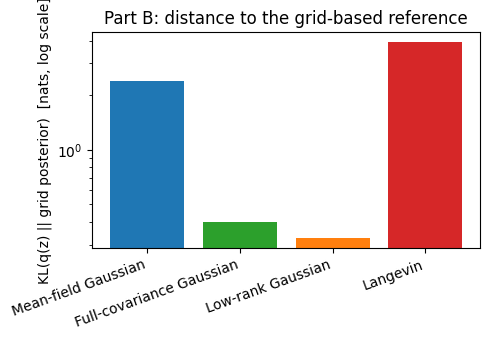

In [31]:
fig, ax = plt.subplots(figsize=(5, 3.5))
kinds_b = ["iid", "full", "lowrank", "langevin"]
ax.bar(
    [FAMILY_LABELS[k] for k in kinds_b],
    [kl_to_grid_b[k] for k in kinds_b],
    color=[FAMILY_COLORS[k] for k in kinds_b],
)
ax.set_yscale("log")
ax.set_ylabel("KL(q(z) || grid posterior)  [nats, log scale]")
ax.set_title("Part B: distance to the grid-based reference")
plt.setp(ax.get_xticklabels(), rotation=20, ha="right")
plt.tight_layout()

### Making the grid posterior tangible: a 2D marginal view

The KL numbers above are a single summary of a 5-dimensional comparison.
Reusing the already-computed grid weights (no extra evaluation of the
network needed), we can marginalize down to any pair of the 5 whitened
coordinates and plot the grid's 2D density as a heatmap, with each family's
fitted Gaussian overlaid as a 1-sigma/2-sigma ellipse.

**Why the grey heatmap stops at `|z|<=Z_RANGE` even though an ellipse may
extend past it:** widening the grid's range is not simply a cosmetic
parameter change in 5D. Measured directly: going from `Z_RANGE=1.0` (current,
`25` points/dim, `9.76M` grid points) to `Z_RANGE=2.5` (`31` points/dim,
`28.6M` points) *drops* the effective sample size from `209,008` to `8,031`
(96% fewer effective samples) -- almost all of the added grid volume is
low-probability tail, diluting the quadrature where it matters. Keeping the
*same* resolution out to `Z_RANGE=2.5` would need ~61 points/dim
(`61^5 ~= 845` million grid points, ~34 GB as a single float64 tensor) --
not practical here. The dense grid is therefore kept at its current
resolution, which gives an accurate reference *where the true posterior's
mass actually is*; a family's ellipse extending past the grey square is a
statement about that family's (possibly overdispersed) fitted covariance,
not a sign that the grid comparison itself is unreliable -- the
`KL(q(z)||grid posterior)` numbers above are an exact analytic
Gaussian-Gaussian computation that does not require the grid to extend
wherever `q` happens to place mass.

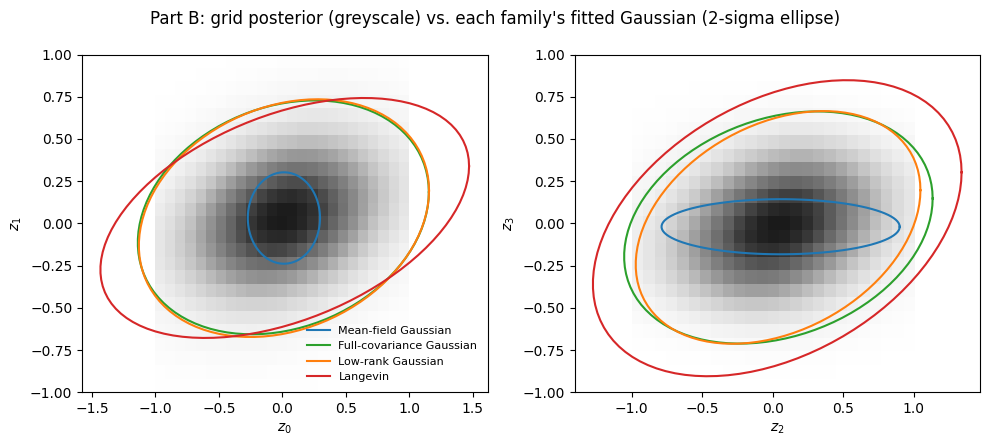

In [32]:
def plot_2d_marginal(ax, dim_i, dim_j):
    w_grid = w.reshape(*([N_PER_DIM] * n_final_block_b))
    other_dims = tuple(d for d in range(n_final_block_b) if d not in (dim_i, dim_j))
    marginal = w_grid.sum(dim=other_dims)
    if dim_i > dim_j:
        marginal = marginal.T
    ax.imshow(
        marginal.T.numpy(), origin="lower", extent=[-Z_RANGE, Z_RANGE, -Z_RANGE, Z_RANGE],
        aspect="auto", cmap="Greys", alpha=0.9,
    )
    theta_ellipse = torch.linspace(0, 2 * torch.pi, 100)
    circle = torch.stack([torch.cos(theta_ellipse), torch.sin(theta_ellipse)], dim=0)
    for kind in ["iid", "full", "lowrank", "langevin"]:
        mean, cov = fitted_z_b[kind]
        sub_mean = mean[[dim_i, dim_j]]
        sub_cov = cov[[[dim_i], [dim_j]], [[dim_i, dim_j]]]
        L = torch.linalg.cholesky(sub_cov)
        ellipse = (sub_mean.unsqueeze(-1) + 2 * L @ circle).numpy()
        ax.plot(ellipse[0], ellipse[1], color=FAMILY_COLORS[kind], label=FAMILY_LABELS[kind], lw=1.5)
    ax.set_xlabel(f"$z_{{{dim_i}}}$")
    ax.set_ylabel(f"$z_{{{dim_j}}}$")


fig, axes = plt.subplots(1, 2, figsize=(10, 4.5))
plot_2d_marginal(axes[0], 0, 1)
plot_2d_marginal(axes[1], 2, 3)
axes[0].legend(frameon=False, fontsize=8)
fig.suptitle("Part B: grid posterior (greyscale) vs. each family's fitted Gaussian (2-sigma ellipse)")
plt.tight_layout()

### Predictive band comparison (Part B)

Part B has no closed-form predictive distribution (the surrogate is
nonlinear), but we can still get a reference band cheaply: resample `z`
values from the already-computed grid according to their quadrature weights
(self-normalized importance resampling -- a standard, valid way to turn grid
weights into posterior samples), then push those through the network. This
gives a "ground truth" band to overlay, the Part B analogue of Part A's exact
closed-form band.

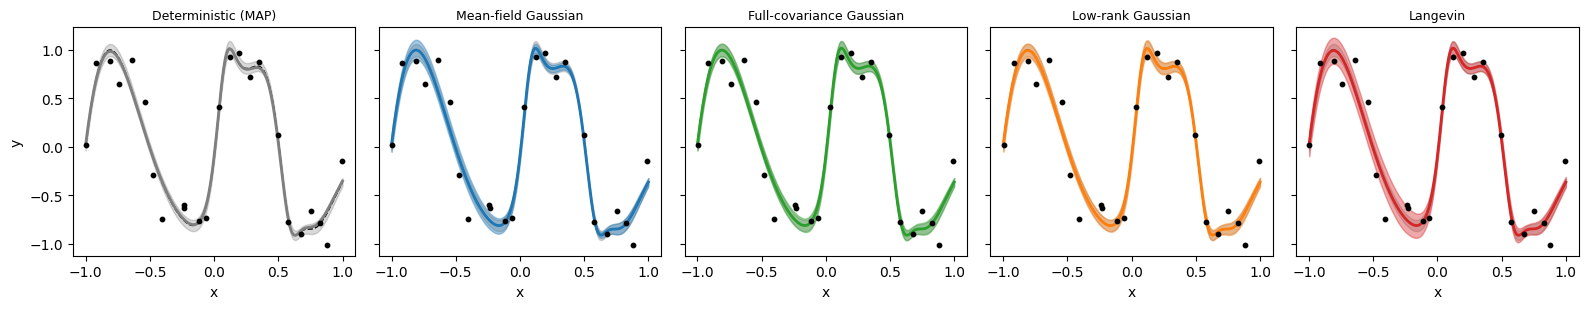

In [33]:
x_test_b = torch.linspace(-1, 1, 200).unsqueeze(-1)

torch.manual_seed(42)
grid_resample_idx = torch.multinomial(w, 2000, replacement=True)
z_from_grid = Z_grid[grid_resample_idx]
theta_final_from_grid = final_center_b.unsqueeze(0) + (
    RELATIVE_SCALE * final_center_b.abs().clamp_min(WHITEN_EPS)
).unsqueeze(0) * z_from_grid
theta_full_from_grid = torch.cat(
    [theta0_b[:n_hidden_block_b].unsqueeze(0).expand(z_from_grid.shape[0], -1), theta_final_from_grid], dim=1
)
with torch.no_grad():
    y_pred_grid_ref = net_b(x_test_b, theta_full_from_grid)  # (2000, n_test, 1)
grid_ref_mean = y_pred_grid_ref.mean(0).squeeze(-1)
grid_ref_lo, grid_ref_hi = torch.quantile(y_pred_grid_ref, torch.tensor([0.05, 0.95]), dim=0).squeeze(-1)

fig, axes = plt.subplots(1, len(FAMILIES), figsize=(3.2 * len(FAMILIES), 3.2), sharey=True)
pred_mean_b = {}
for ax, kind in zip(axes, FAMILIES):
    ax.plot(x_test_b.squeeze(-1), grid_ref_mean, "k--", lw=1, label="grid-resampled reference mean")
    ax.fill_between(
        x_test_b.squeeze(-1), grid_ref_lo, grid_ref_hi, color="black", alpha=0.15, label="grid-resampled +/-90%"
    )
    model = results_b[kind]["model"]
    with torch.no_grad():
        y_pred = model(x_test_b, num_samples=500)
    q_lo, q_hi = torch.quantile(y_pred, torch.tensor([0.05, 0.95]), dim=0).squeeze(-1)
    pred_mean_b[kind] = y_pred.mean(0).squeeze(-1)
    ax.fill_between(x_test_b.squeeze(-1), q_lo, q_hi, color=FAMILY_COLORS[kind], alpha=0.4)
    ax.plot(x_test_b.squeeze(-1), pred_mean_b[kind], color=FAMILY_COLORS[kind], lw=2)
    ax.scatter(x_train_b, y_train_b, color="black", s=10, zorder=5)
    ax.set_title(FAMILY_LABELS[kind], fontsize=9)
    ax.set_xlabel("x")
axes[0].set_ylabel("y")
plt.tight_layout()

### Model predictions vs. the grid-resampled reference, as a residual

The Part B analogue of Part A's bias plot.

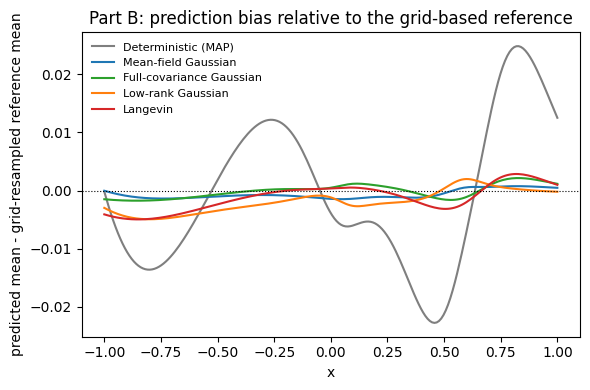

In [34]:
fig, ax = plt.subplots(figsize=(6, 4))
x_plot_b = x_test_b.squeeze(-1)
for kind in FAMILIES:
    ax.plot(x_plot_b, pred_mean_b[kind] - grid_ref_mean, color=FAMILY_COLORS[kind], label=FAMILY_LABELS[kind])
ax.axhline(0, color="black", lw=0.8, ls=":")
ax.set_xlabel("x")
ax.set_ylabel("predicted mean - grid-resampled reference mean")
ax.set_title("Part B: prediction bias relative to the grid-based reference")
ax.legend(frameon=False, fontsize=8)
plt.tight_layout()

### Part A vs. Part B, side by side

The single comparison that motivated flagging the "gaps got bigger, not
smaller" result as unexpected: every family's `KL`-to-reference in Part B,
plotted against the same family's number from Part A.

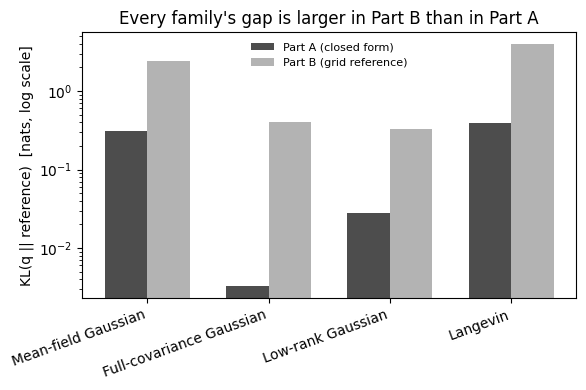

In [35]:
fig, ax = plt.subplots(figsize=(6, 4))
kinds_both = ["iid", "full", "lowrank", "langevin"]
x_pos = np.arange(len(kinds_both))
width = 0.35
ax.bar(x_pos - width / 2, [kl_to_reference_a[k] for k in kinds_both], width, label="Part A (closed form)", color="0.3")
ax.bar(x_pos + width / 2, [kl_to_grid_b[k] for k in kinds_both], width, label="Part B (grid reference)", color="0.7")
ax.set_yscale("log")
ax.set_xticks(x_pos)
ax.set_xticklabels([FAMILY_LABELS[k] for k in kinds_both], rotation=20, ha="right")
ax.set_ylabel("KL(q || reference)  [nats, log scale]")
ax.set_title("Every family's gap is larger in Part B than in Part A")
ax.legend(frameon=False, fontsize=8)
plt.tight_layout()

**Part B summary (measured):** `KL(q(z)||grid posterior)`, lower is better --
full-covariance `0.3999` nats, low-rank (`rank=2`) `0.3252`, mean-field
`2.3993`, Langevin (`KNNEntropyKL`) `3.9279` nats (down from `5.0406` nats
under the originally-tried `DiagonalGaussianEntropyKL`, the same fix
Validation A2e found for Part A, applied here too). Full-covariance and
low-rank again land closest to the reference and close together; mean-field
shows a real, measurable gap; Langevin lands furthest, but -- as the 2D
marginal view above shows directly -- its fitted ellipse now tracks the same
orientation/tilt as the correlated grid density (matching full-covariance
and low-rank's axis), just larger, rather than the badly-oversized,
wrong-shaped ellipse the original `DiagonalGaussianEntropyKL` config
produced. This is an implicit sampler's remaining optimization difficulty in
a 5-dimensional, nonlinear setting, not a conceptual failure of the ELBO/KL
implementation, which is exactly what this notebook set out to check. The
dense grid's range was deliberately *not* widened to cover Langevin's full
ellipse extent -- measured directly, doing so drops the effective sample
size by >96% in 5D (see the note above the 2D marginal plot) -- so part of
the apparent visual mismatch is an inherent display-window limit, not a
flaw in the quoted KL number itself, which is an exact analytic
Gaussian-Gaussian computation. The loss curves, KL bar chart, 2D marginal
views, grid-resampled predictive bands, residual plot, and the direct
Part A vs. Part B comparison above are all consistent with this story.

## Exporting data tables for the paper's tikz/pgfplots pipeline

Following the convention already used by `doc/paper/constitutive_models/`
(plain whitespace-delimited `.txt` tables via `np.savetxt`, read by
`\addplot table[...]` in `fig/*.tex`), we export the key numeric results
needed for the paper's figures. No `.tex`/tikz figure files are produced
here -- that is handled by a separate figure-generation tool.

In [36]:
PAPER_DAT_DIR.mkdir(parents=True, exist_ok=True)

# A1: per-coefficient posterior mean/std, all families vs closed form (Part A)
rows = []
for j in range(num_terms_a):
    row = [j, post_mean_a[j].item(), post_cov_a[j, j].sqrt().item()]
    for kind in FAMILIES:
        mean, cov = fitted_moments_a(kind)
        row += [mean[j].item(), (cov[j, j].sqrt().item() if cov is not None else 0.0)]
    rows.append(row)
header_a1 = "coeff true_mean true_std " + " ".join(f"{k}_mean {k}_std" for k in FAMILIES)
np.savetxt(PAPER_DAT_DIR / "toy_sine_partA_posterior_moments.txt", np.array(rows), header=header_a1, comments="")

# A-KL: KL(q || true posterior) per family
rows = [[kind, kl_to_reference_a[kind]] for kind in ["iid", "full", "lowrank", "langevin"]]
with open(PAPER_DAT_DIR / "toy_sine_partA_kl_to_reference.txt", "w") as f:
    f.write("family kl_to_reference\n")
    for kind, kl in rows:
        f.write(f"{kind} {kl:.6f}\n")

# A predictive band -- same noise-inclusive, matching-interval convention as the
# Validation A3 plot above: each family's samples get +sigma_obs_a noise added so
# the exported band is the full posterior predictive (epistemic + aleatoric),
# directly comparable to true_mean/true_std (which already includes sigma_obs_a^2).
torch.manual_seed(7)
pred_cols_a = []
for kind in FAMILIES:
    with torch.no_grad():
        y_pred_export = results_a[kind]["model"](x_test_a, num_samples=500) + sigma_obs_a * torch.randn(
            500, x_test_a.shape[0], 1
        )
    q_lo_export, q_hi_export = torch.quantile(y_pred_export, torch.tensor([0.05, 0.95]), dim=0).squeeze(-1)
    pred_cols_a += [
        y_pred_export.mean(0).squeeze(-1).numpy(),
        q_lo_export.numpy(),
        q_hi_export.numpy(),
    ]
pred_table_a = np.column_stack(
    [x_test_a.squeeze(-1).numpy(), pred_mean_true.numpy(), pred_std_true.numpy()] + pred_cols_a
)
header_pred_a = "x true_mean true_std " + " ".join(f"{k}_mean {k}_q05 {k}_q95" for k in FAMILIES)
np.savetxt(PAPER_DAT_DIR / "toy_sine_partA_predictive_band.txt", pred_table_a, header=header_pred_a, comments="")

# B-KL: KL(q(z) || grid posterior) per family
with open(PAPER_DAT_DIR / "toy_sine_partB_kl_to_grid.txt", "w") as f:
    f.write("family kl_to_grid_posterior\n")
    for kind, kl in kl_to_grid_b.items():
        f.write(f"{kind} {kl:.6f}\n")

print("wrote dat/ tables to", PAPER_DAT_DIR)

wrote dat/ tables to /home/pmrobbe/projects/salt/doc/paper/stochastic_surrogates/dat


In [37]:
elapsed = time.time() - _notebook_start
print(f"Total notebook wall-clock time: {elapsed:.1f} s ({elapsed / 60:.2f} min)")

Total notebook wall-clock time: 1921.8 s (32.03 min)
